# Rent 04 · Explore bedbug reports and evictions
| Dataset | What it is | For the renter |
|---|---|---|
| [Bedbug Reporting](https://data.cityofnewyork.us/d/wz6d-d3jb) | Landlords of 3+ unit buildings must file **yearly**: units, infested units, eradicated, re-infested | "This building had bedbugs in 2 of the last 3 years" |
| [Evictions](https://data.cityofnewyork.us/d/6z8x-wfk4) | Evictions executed by NYC marshals, by address | A signal of landlord behavior (Q2) |

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import config, housing as H, preprocess as P
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 80)

pluto = pd.read_parquet(config.CLEAN_PLUTO_FILE, columns=["bbl", "is_residential", "unitsres", "yearbuilt"])
pluto_bbls = set(pluto["bbl"])
residential_bbls = set(pluto.loc[pluto["is_residential"], "bbl"])

## Part A: Bedbugs

In [2]:
bb = H.load("bedbugs")
print(f"{len(bb):,} filings")
H.overview(bb)

727,059 filings


,missing_%,distinct,example
building_id,0.00,135355,807831
registration_id,0.00,134973,328627
borough,0.00,5,BROOKLYN
house_number,0.00,15939,1146
street_name,0.00,4068,BRIGHTON BEACH AVENUE
postcode,0.00,186,11235
of_dwelling_units,0.00,794,159
infested_dwelling_unit_count,0.00,83,0
eradicated_unit_count,0.00,168,0
re_infested_dwelling_unit,0.00,53,0


In [3]:
for col in ["of_dwelling_units", "infested_dwelling_unit_count", "eradicated_unit_count", "re_infested_dwelling_unit"]:
    bb[col] = pd.to_numeric(bb[col], errors="coerce")
bb["period_end"] = pd.to_datetime(bb["filling_period_end_date"].astype(str), errors="coerce")
bb["year"] = bb["period_end"].dt.year
yearly = bb.groupby("year").agg(filings=("bbl", "size"), buildings=("bbl", "nunique"),
                                with_infestation=("infested_dwelling_unit_count", lambda s: (s > 0).mean()),
                                infested_units=("infested_dwelling_unit_count", "sum"),
                                units=("of_dwelling_units", "sum"))
yearly["infested_per_1000_units"] = yearly.infested_units / yearly.units * 1000
yearly

,filings,buildings,with_infestation,infested_units,units,infested_per_1000_units
year,,,,,,
"2,018.00",37119,30947,0.17,15937,1425979,11.18
"2,019.00",33815,28445,0.14,11303,1263684,8.94
"2,020.00",96472,82980,0.06,17213,2326175,7.40
"2,021.00",97876,82400,0.04,9424,2501612,3.77
"2,022.00",106604,90077,0.04,9512,2955665,3.22
"2,023.00",117172,99277,0.03,837723,4471833,187.33
"2,024.00",118311,100571,0.03,422360,3600961,117.29
"2,025.00",119561,103440,0.03,421945,3164930,133.32


In [4]:
# Data quality: impossible values
print("Infested > units:", (bb.infested_dwelling_unit_count > bb.of_dwelling_units).sum())
print("Negative counts:", (bb[["infested_dwelling_unit_count", "eradicated_unit_count"]] < 0).any(axis=1).sum())
print(f"BBL match to PLUTO: {H.coverage(bb['bbl'], pluto_bbls):.1%}")
print(f"Filings per building per year (duplicates?): {bb.groupby(['bbl', 'year']).size().gt(1).mean():.1%} have >1")

Infested > units: 0
Negative counts: 0


BBL match to PLUTO: 99.8%
Filings per building per year (duplicates?): 10.6% have >1


In [5]:
# Preview of Q1 for bedbugs: infested one year → infested the next?
inf = bb[bb.infested_dwelling_unit_count > 0][["bbl", "year"]].dropna()
last_two = sorted(inf.year.dropna().unique())[-3:-1]
filed = bb[bb.year.isin(last_two)].groupby("bbl")["year"].nunique().eq(2)
both_years = set(filed[filed].index)                       # buildings that filed in both years
y1, y2 = last_two
had = set(inf[inf.year == y1].bbl) & both_years
again = set(inf[inf.year == y2].bbl) & both_years
p_again = len(had & again) / len(had)
p_new = len(again - had) / len(both_years - had)
print(f"Of buildings infested in {y1:.0f}, {p_again:.0%} were infested again in {y2:.0f}; "
      f"of buildings clean in {y1:.0f}, {p_new:.1%} became infested ({p_again / p_new:.0f}x difference)")

Of buildings infested in 2023, 39% were infested again in 2024; of buildings clean in 2023, 1.8% became infested (22x difference)


## Part B: Evictions

In [6]:
ev = H.load("evictions")
print(f"{len(ev):,} evictions")
display(H.overview(ev))
ev["executed_date"] = pd.to_datetime(ev["executed_date"].astype(str), errors="coerce")
ev["year"] = ev["executed_date"].dt.year
pd.crosstab(ev["year"], ev["residential_commercial_ind"])

137,724 evictions


,missing_%,distinct,example
court_index_number,0.00,125827,309704/22
docket_number,0.00,117342,107979
eviction_address,0.00,75866,"1192 FULTON STREET GROUND FLOOR,APPOX. 1600 GROSS PLUS BASEMENT-SALE"
eviction_apt_num,14.30,12707,2C
executed_date,0.00,2068,2023-03-13T00:00:00.000
marshal_first_name,0.00,28,Henry
marshal_last_name,0.00,31,Daley
residential_commercial_ind,0.00,4,Commercial
borough,0.00,8,BROOKLYN
eviction_zip,0.00,267,11216


residential_commercial_ind,C,Commercial,R,Residential
year,,,,
2017,0,1719,0,20803
2018,0,1842,0,19988
2019,0,1677,0,17036
2020,0,358,0,3064
2021,0,108,0,160
2022,0,969,0,4029
2023,0,1367,0,12025
2024,0,1270,0,15461
2025,0,1513,2,17789


In [7]:
res = ev[ev["residential_commercial_ind"].astype(str).str.upper().str.startswith("RES")]
print(f"Residential evictions: {len(res):,}; with BBL: {res['bbl'].notna().mean():.1%}; "
      f"BBL match to PLUTO: {H.coverage(res['bbl'], pluto_bbls):.1%}")
per_bldg = res.dropna(subset=["bbl"]).groupby("bbl").size()
display(H.concentration(per_bldg).map("{:.0%}".format).to_frame("share of evictions").T)
per_bldg.sort_values(ascending=False).head(10).to_frame("evictions (all years)")

Residential evictions: 125,344; with BBL: 93.2%; BBL match to PLUTO: 98.9%


,top 1%,top 5%,top 10%
share of evictions,14%,32%,44%


,evictions (all years)
bbl,
2028820229,396
2051410120,324
4159260001,292
4124950002,277
2039447501,248
2039437501,212
4156100001,204
3036280001,142
3042719001,121


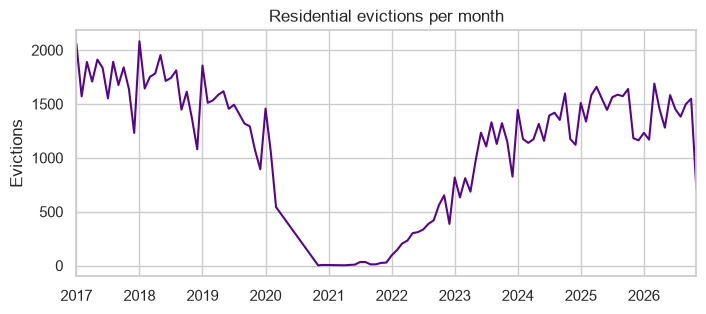

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
res.groupby(res["executed_date"].dt.to_period("M")).size().plot(ax=ax, color=ACCENT)
ax.set(title="Residential evictions per month", xlabel="", ylabel="Evictions")
save(fig, "rent04a_evictions_per_month")

## Takeaways
- **Bedbugs:** yearly building-level data with a clean BBL. Strong year-to-year persistence makes it a good feature *and* a good thing to predict. Filings that report more infested units than units exist must be dropped in cleaning.
- **Evictions:** the 2020–21 moratorium shows as a gap, so use 2022+ only. Rates should be per apartment (PLUTO units). Evictions are better as a **landlord-level** signal (summed over the portfolio) than per building, because counts per building are small.

**Exploration done.** → Next: the cleaning notebooks, then one-row-per-building feature table.